# RotaLivre — Análise Exploratória de Dados

## Global Solution 2026/2 — CitizenTech

O RotaLivre é uma solução tecnológica colaborativa que busca facilitar a identificação das condições de acessibilidade em locais urbanos.

O projeto tem como objetivo ajudar pessoas com deficiência, idosos e pessoas com mobilidade reduzida a encontrar informações sobre a acessibilidade de calçadas, rampas, elevadores, estabelecimentos e possíveis obstáculos urbanos.

### Objetivos desta análise

- Conhecer a estrutura da base de dados.
- Identificar valores ausentes e registros duplicados.
- Analisar as características físicas dos locais.
- Investigar a distribuição das classificações de acessibilidade.
- Visualizar a distribuição geográfica dos pontos.
- Preparar os dados para o desenvolvimento dos modelos de Inteligência Artificial.

### Origem dos dados

Nesta primeira etapa, utilizamos 600 registros sintéticos e simulados, criados exclusivamente para desenvolver e testar os modelos enquanto a base oficial do projeto não está disponível.

**Importante:** os dados não representam avaliações reais de acessibilidade.

In [1]:
# Importação das bibliotecas utilizadas na análise.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuração visual dos gráficos.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [2]:
# Identifica a localização da pasta principal do projeto.
pasta_atual = Path.cwd()

if pasta_atual.name == "notebooks":
    raiz_projeto = pasta_atual.parent
else:
    raiz_projeto = pasta_atual

# Localiza o arquivo CSV dentro da pasta dados.
caminho_csv = raiz_projeto / "dados" / "locais_acessibilidade.csv"

# Carrega os dados utilizando Pandas.
df = pd.read_csv(caminho_csv)

print("Base de dados carregada com sucesso!")
print("Local do arquivo:", caminho_csv)
print("Quantidade de registros:", len(df))

# Apresenta os primeiros registros.
display(df.head())

Base de dados carregada com sucesso!
Local do arquivo: c:\Users\usuario\Desktop\fiap-2sem\gs\RotaLivre-IA\dados\locais_acessibilidade.csv
Quantidade de registros: 600


,id_local,tipo_local,largura_calcada_m,inclinacao_graus,rampa,piso_tatil,piso_regular,sinalizacao_acessivel,quantidade_relatos,usuarios_distintos,nota_acessibilidade,situacao_acessibilidade,latitude,longitude,origem_dados
0,1,ESTABELECIMENTO,2.40,13.18,0,0,0,1,2,2,52,PARCIAL,-23.529384,-46.654258,SINTETICO_SIMULADO
1,2,ELEVADOR,0.49,17.46,1,1,1,1,15,11,52,PARCIAL,-23.585950,-46.609499,SINTETICO_SIMULADO
2,3,CALCADA,1.53,7.20,1,1,1,1,14,13,86,ACESSIVEL,-23.575230,-46.618999,SINTETICO_SIMULADO
3,4,CALCADA,0.55,10.94,0,0,0,1,3,0,35,INACESSIVEL,-23.576061,-46.613433,SINTETICO_SIMULADO
4,5,RAMPA,1.85,7.92,0,1,0,1,14,2,65,PARCIAL,-23.532210,-46.623183,SINTETICO_SIMULADO


In [3]:
# Verifica a quantidade de linhas e colunas.
print("Dimensões da base:")
print(df.shape)

# Apresenta informações sobre as colunas.
print("\nInformações gerais:")
df.info()

# Exibe os tipos de dados.
print("\nTipos de dados:")
display(df.dtypes)

# Apresenta estatísticas das variáveis numéricas.
print("\nEstatísticas descritivas:")
display(df.describe())

Dimensões da base:
(600, 15)

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_local                 600 non-null    int64  
 1   tipo_local               600 non-null    str    
 2   largura_calcada_m        600 non-null    float64
 3   inclinacao_graus         600 non-null    float64
 4   rampa                    600 non-null    int64  
 5   piso_tatil               600 non-null    int64  
 6   piso_regular             600 non-null    int64  
 7   sinalizacao_acessivel    600 non-null    int64  
 8   quantidade_relatos       600 non-null    int64  
 9   usuarios_distintos       600 non-null    int64  
 10  nota_acessibilidade      600 non-null    int64  
 11  situacao_acessibilidade  600 non-null    str    
 12  latitude                 600 non-null    float64
 13  longitude                600 non-null    

id_local                     int64
tipo_local                     str
largura_calcada_m          float64
inclinacao_graus           float64
rampa                        int64
piso_tatil                   int64
piso_regular                 int64
sinalizacao_acessivel        int64
quantidade_relatos           int64
usuarios_distintos           int64
nota_acessibilidade          int64
situacao_acessibilidade        str
latitude                   float64
longitude                  float64
origem_dados                   str
dtype: object


Estatísticas descritivas:


,id_local,largura_calcada_m,inclinacao_graus,rampa,piso_tatil,piso_regular,sinalizacao_acessivel,quantidade_relatos,usuarios_distintos,nota_acessibilidade,latitude,longitude
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,300.500000,1.469117,8.967150,0.491667,0.495000,0.470000,0.520000,7.676667,3.898333,57.146667,-23.546923,-46.630827
std,173.349358,0.574196,5.070273,0.500348,0.500392,0.499516,0.500017,4.611677,3.790155,16.305672,0.020593,0.020897
min,1.000000,0.450000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,13.000000,-23.586089,-46.669957
25%,150.750000,0.970000,4.685000,0.000000,0.000000,0.000000,0.000000,4.000000,1.000000,46.000000,-23.572560,-46.655913
50%,300.500000,1.500000,8.930000,0.000000,0.000000,0.000000,1.000000,8.000000,3.000000,57.000000,-23.535874,-46.619405
75%,450.250000,1.940000,13.392500,1.000000,1.000000,1.000000,1.000000,12.000000,6.000000,68.000000,-23.530954,-46.614334
max,600.000000,2.490000,17.900000,1.000000,1.000000,1.000000,1.000000,15.000000,15.000000,93.000000,-23.516516,-46.602774


In [4]:
# Verifica valores ausentes em cada coluna.
print("Valores ausentes:")
display(df.isnull().sum())

# Verifica registros duplicados.
print("\nRegistros duplicados:")
print(df.duplicated().sum())

# Verifica identificadores repetidos.
print("\nIDs duplicados:")
print(df["id_local"].duplicated().sum())

# Verifica a origem dos registros.
print("\nOrigem dos dados:")
display(df["origem_dados"].value_counts())

Valores ausentes:


id_local                   0
tipo_local                 0
largura_calcada_m          0
inclinacao_graus           0
rampa                      0
piso_tatil                 0
piso_regular               0
sinalizacao_acessivel      0
quantidade_relatos         0
usuarios_distintos         0
nota_acessibilidade        0
situacao_acessibilidade    0
latitude                   0
longitude                  0
origem_dados               0
dtype: int64


Registros duplicados:
0

IDs duplicados:
0

Origem dos dados:


origem_dados
SINTETICO_SIMULADO    600
Name: count, dtype: int64

tipo_local
ESTABELECIMENTO    135
RAMPA              135
OBSTACULO          117
ELEVADOR           111
CALCADA            102
Name: count, dtype: int64

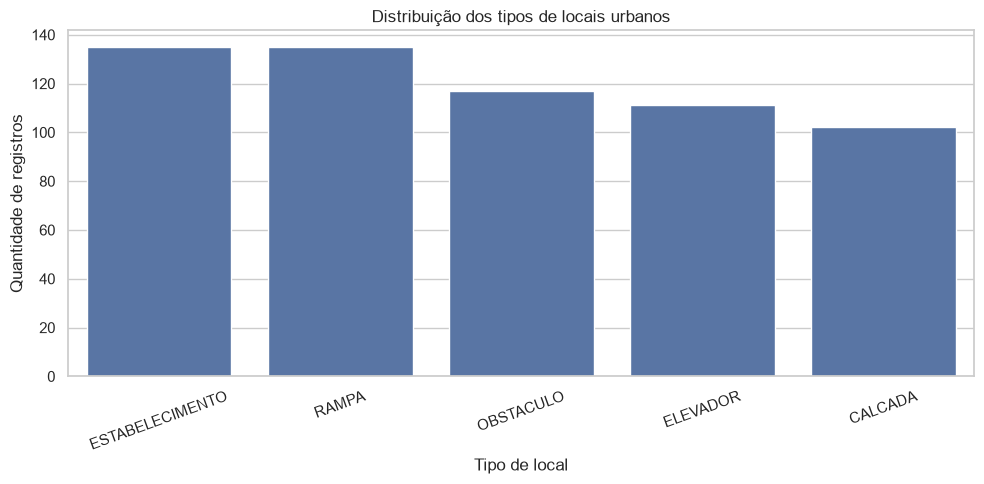

In [5]:
# Conta quantos registros existem para cada tipo de local.
tipos = df["tipo_local"].value_counts()

display(tipos)

# Cria um gráfico com a distribuição dos tipos.
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="tipo_local",
    order=tipos.index
)

plt.title("Distribuição dos tipos de locais urbanos")
plt.xlabel("Tipo de local")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

Quantidade por classificação:


situacao_acessibilidade
PARCIAL        365
ACESSIVEL      138
INACESSIVEL     97
Name: count, dtype: int64

Percentual por classificação:


situacao_acessibilidade
PARCIAL        60.83
ACESSIVEL      23.00
INACESSIVEL    16.17
Name: proportion, dtype: float64

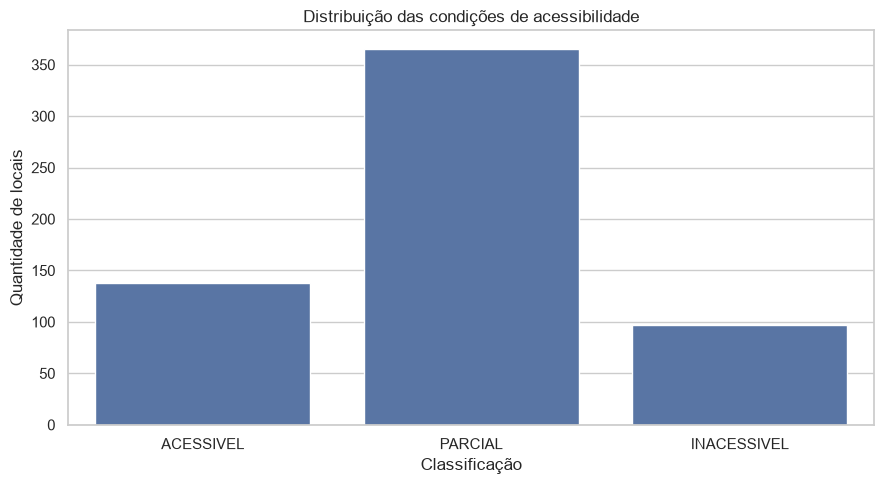

In [6]:
# Conta a quantidade de registros por classificação.
distribuicao = df["situacao_acessibilidade"].value_counts()

print("Quantidade por classificação:")
display(distribuicao)

# Calcula o percentual de cada classificação.
percentuais = (
    df["situacao_acessibilidade"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Percentual por classificação:")
display(percentuais)

# Cria o gráfico.
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="situacao_acessibilidade",
    order=["ACESSIVEL", "PARCIAL", "INACESSIVEL"]
)

plt.title("Distribuição das condições de acessibilidade")
plt.xlabel("Classificação")
plt.ylabel("Quantidade de locais")

plt.tight_layout()
plt.show()

Estatísticas da largura das calçadas:


count    600.000000
mean       1.469117
std        0.574196
min        0.450000
25%        0.970000
50%        1.500000
75%        1.940000
max        2.490000
Name: largura_calcada_m, dtype: float64

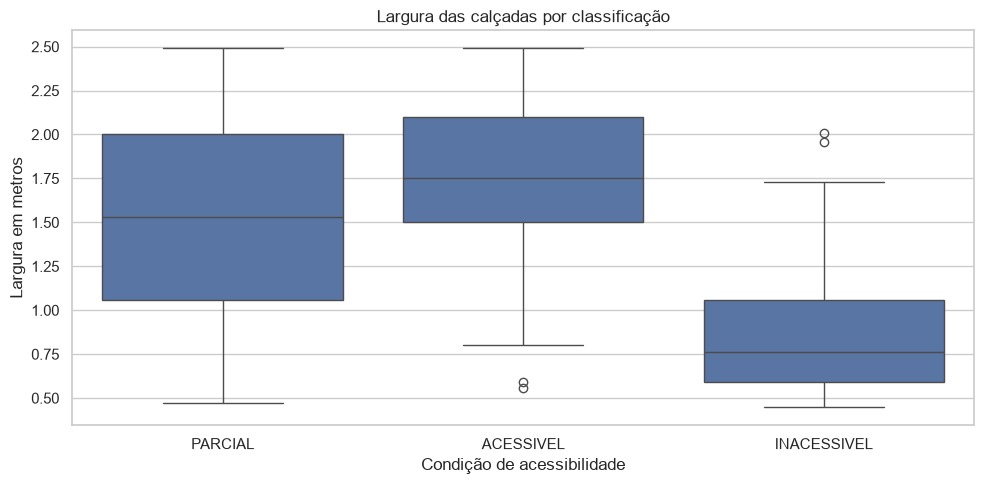

In [7]:
# Calcula estatísticas da largura das calçadas.
print("Estatísticas da largura das calçadas:")
display(df["largura_calcada_m"].describe())

# Compara a largura entre as classificações.
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="situacao_acessibilidade",
    y="largura_calcada_m"
)

plt.title("Largura das calçadas por classificação")
plt.xlabel("Condição de acessibilidade")
plt.ylabel("Largura em metros")

plt.tight_layout()
plt.show()

Estatísticas da inclinação:


count    600.000000
mean       8.967150
std        5.070273
min        0.010000
25%        4.685000
50%        8.930000
75%       13.392500
max       17.900000
Name: inclinacao_graus, dtype: float64

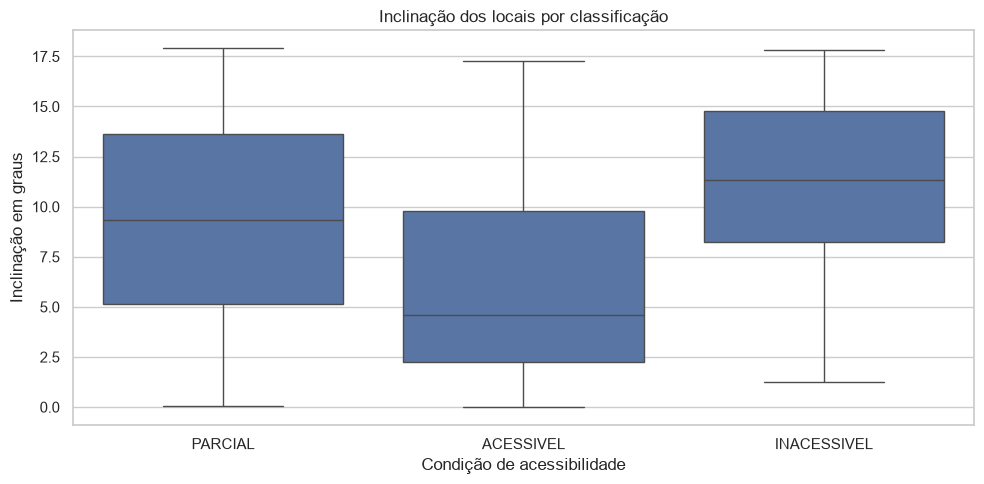

In [8]:
# Apresenta estatísticas sobre a inclinação.
print("Estatísticas da inclinação:")
display(df["inclinacao_graus"].describe())

# Compara a inclinação entre as classificações.
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="situacao_acessibilidade",
    y="inclinacao_graus"
)

plt.title("Inclinação dos locais por classificação")
plt.xlabel("Condição de acessibilidade")
plt.ylabel("Inclinação em graus")

plt.tight_layout()
plt.show()

Presença dos recursos por classificação (%):


,rampa,piso_tatil,piso_regular,sinalizacao_acessivel
situacao_acessibilidade,,,,
ACESSIVEL,72.46,75.36,71.01,71.74
INACESSIVEL,22.68,21.65,26.80,30.93
PARCIAL,47.40,47.12,43.29,50.14


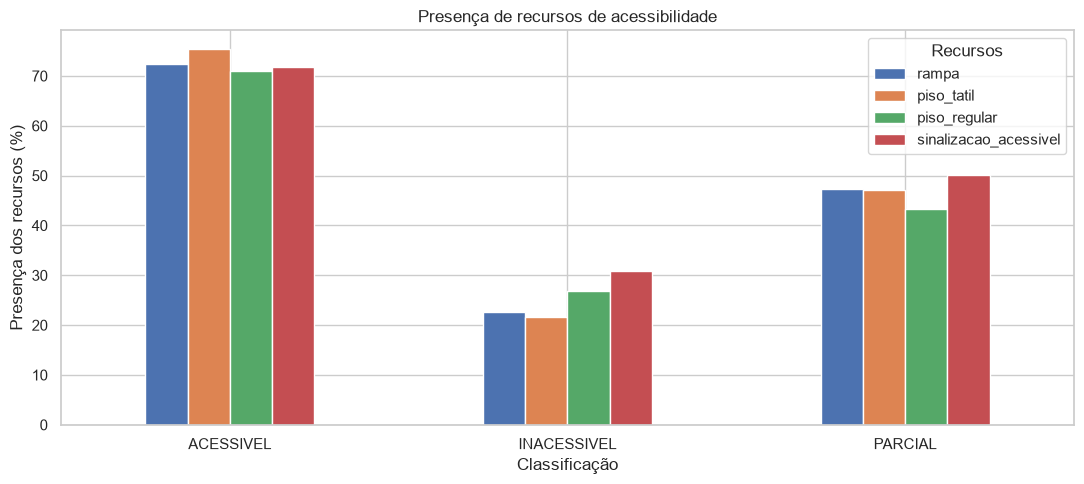

In [9]:
# Lista dos recursos disponíveis na base.
recursos = [
    "rampa",
    "piso_tatil",
    "piso_regular",
    "sinalizacao_acessivel"
]

# Calcula a presença média dos recursos por classificação.
analise_recursos = (
    df.groupby("situacao_acessibilidade")[recursos]
    .mean()
    .mul(100)
    .round(2)
)

print("Presença dos recursos por classificação (%):")
display(analise_recursos)

# Cria um gráfico comparativo.
analise_recursos.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Presença de recursos de acessibilidade")
plt.xlabel("Classificação")
plt.ylabel("Presença dos recursos (%)")
plt.xticks(rotation=0)
plt.legend(title="Recursos")

plt.tight_layout()
plt.show()

In [10]:
# Analisa a quantidade de relatos e usuários distintos.
print("Estatísticas dos relatos:")
display(
    df[
        ["quantidade_relatos", "usuarios_distintos"]
    ].describe()
)

# Conta locais com pelo menos três usuários distintos.
locais_confirmaveis = (
    df["usuarios_distintos"] >= 3
).sum()

print(
    "Locais com pelo menos três usuários distintos:",
    locais_confirmaveis
)

print(
    "Locais com menos de três usuários distintos:",
    len(df) - locais_confirmaveis
)

Estatísticas dos relatos:


,quantidade_relatos,usuarios_distintos
count,600.000000,600.000000
mean,7.676667,3.898333
std,4.611677,3.790155
min,0.000000,0.000000
25%,4.000000,1.000000
50%,8.000000,3.000000
75%,12.000000,6.000000
max,15.000000,15.000000


Locais com pelo menos três usuários distintos: 322
Locais com menos de três usuários distintos: 278


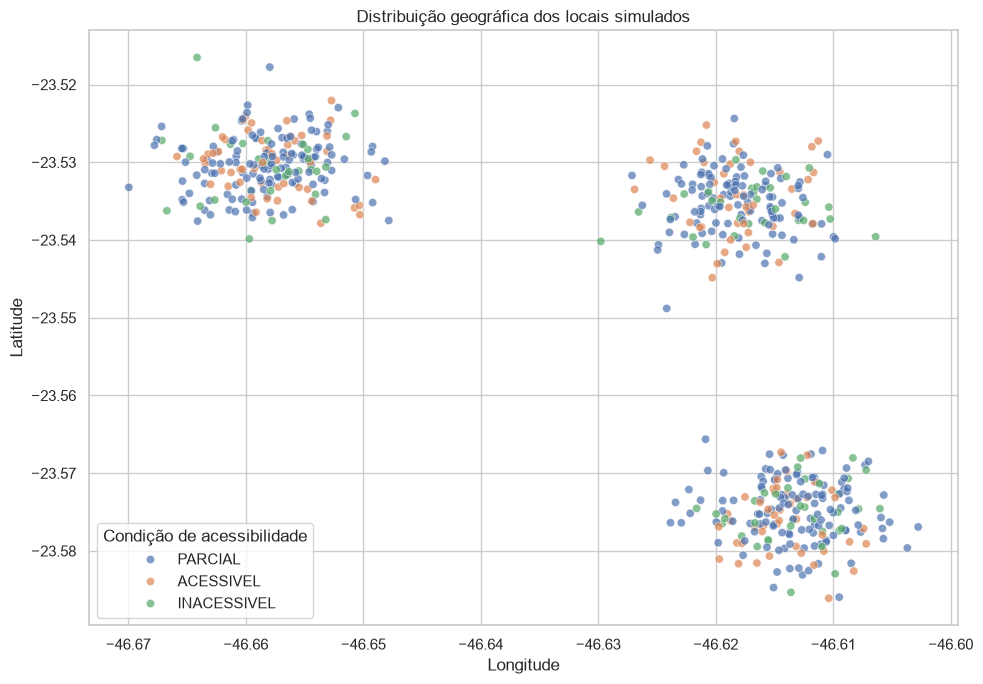

In [11]:
# Visualiza a localização geográfica dos pontos simulados.
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="situacao_acessibilidade",
    alpha=0.7
)

plt.title("Distribuição geográfica dos locais simulados")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Condição de acessibilidade")

plt.tight_layout()
plt.show()

In [12]:
# Lista de colunas obrigatórias para os experimentos.
colunas_obrigatorias = [
    "id_local",
    "tipo_local",
    "largura_calcada_m",
    "inclinacao_graus",
    "rampa",
    "piso_tatil",
    "piso_regular",
    "sinalizacao_acessivel",
    "quantidade_relatos",
    "usuarios_distintos",
    "nota_acessibilidade",
    "situacao_acessibilidade",
    "latitude",
    "longitude",
    "origem_dados"
]

# Identifica possíveis colunas ausentes.
colunas_faltantes = [
    coluna for coluna in colunas_obrigatorias
    if coluna not in df.columns
]

# Classificações permitidas.
classes_validas = [
    "ACESSIVEL",
    "PARCIAL",
    "INACESSIVEL"
]

classes_encontradas = set(df["situacao_acessibilidade"].unique())

print("VALIDAÇÃO DA BASE ROTAlIVRE")
print("-" * 40)

print("Quantidade de registros:", len(df))
print("Quantidade de colunas:", len(df.columns))
print("Colunas faltantes:", colunas_faltantes)
print("Classificações encontradas:", classes_encontradas)

# Verifica se os requisitos básicos foram atendidos.
if (
    len(df) > 0
    and not colunas_faltantes
    and classes_encontradas.issubset(set(classes_validas))
):
    print("\nBase aprovada para os experimentos iniciais!")
else:
    print("\nAtenção: existem problemas que precisam ser corrigidos.")

VALIDAÇÃO DA BASE ROTAlIVRE
----------------------------------------
Quantidade de registros: 600
Quantidade de colunas: 15
Colunas faltantes: []
Classificações encontradas: {'INACESSIVEL', 'PARCIAL', 'ACESSIVEL'}

Base aprovada para os experimentos iniciais!


# Conclusão da Análise Exploratória

A análise exploratória permitiu conhecer a estrutura da base demonstrativa do RotaLivre e investigar características relacionadas à acessibilidade urbana.

Durante esta etapa, foram analisados:

- Os tipos de locais urbanos.
- A distribuição das classificações de acessibilidade.
- A largura e a inclinação dos locais.
- A presença de recursos de acessibilidade.
- A quantidade de relatos e usuários distintos.
- A distribuição geográfica dos pontos.

## Limitações dos dados

Os 600 registros utilizados são sintéticos e foram gerados por regras demonstrativas.

As classificações não representam avaliações reais e não devem ser interpretadas como confirmações oficiais de acessibilidade.

A versão integrada deverá utilizar os dados oficiais do banco Oracle, respeitando as regras de relatos, período de 30 dias e quantidade mínima de usuários distintos.

## Próximas etapas

1. Preparação dos dados para treinamento.
2. Desenvolvimento do modelo de classificação.
3. Desenvolvimento do modelo de agrupamento KMeans.
4. Avaliação dos modelos com métricas adequadas.
5. Exportação dos modelos em arquivos Joblib.
6. Desenvolvimento da API Flask.
7. Integração com os dados e serviços das demais disciplinas.